In [1]:
modules = ["pandas", "numpy", "matplotlib", "missingno", "seaborn"]

import sys
import os.path
from subprocess import check_call
import importlib
import os

def instala(modules):
  print("Instalando módulos")
  for m in modules:
      # para el import quitamos [...] y ==...
      p = m.find("[")
      mi = m if p==-1 else m[:p]
      p = mi.find("==")
      mi = mi if p==-1 else mi[:p]

      torch_loader = importlib.util.find_spec(mi)
      if torch_loader is not None:
          print(m," encontrado")
      else:
          print(m," No encontrado, instalando...",end="")  
          try:        
            r = check_call([sys.executable, "-m", "pip", "install", "--user", m])
            print("¡hecho! (Reiniciar kernel)")
          except:
            print("¡Problema al instalar ",m,"! ¿seguro que el módulo existe?",sep="")
              
  print("¡Terminado!")

instala(modules)

Instalando módulos
pandas  encontrado
numpy  encontrado
matplotlib  encontrado
missingno  encontrado
seaborn  encontrado
¡Terminado!


In [2]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,SMA_200_binance,...,volatilidad_200_dxy,momentum_50_dxy,momentum_200_dxy,var_diaria_dxy,rango_dia_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,2022-03-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.879436,1.080002,77.238708,NaN,0,NaN,0
1,2022-03-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.802543,1.003334,77.979968,NaN,0,NaN,0
2,2022-03-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.725650,0.926666,78.721228,NaN,0,NaN,0
3,2022-03-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.648758,0.849998,79.462488,NaN,0,NaN,0
4,2022-03-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,-0.231648,0.610001,68.885196,NaN,0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1093,2025-03-01,84349.95,86558.00,83824.78,86064.53,25785.05464,3700728.0,2.219179e+09,97742.7420,82128.37695,...,2.394957,0.199997,0.349998,-0.689589,0.610001,38.007314,NaN,0,NaN,0
1094,2025-03-02,86064.54,95000.00,85050.60,94270.00,54889.09045,7403218.0,5.174395e+09,97736.1422,82306.31000,...,2.394957,0.199997,0.349998,-0.689589,0.610001,38.007314,NaN,0,NaN,0
1095,2025-03-03,94269.99,94416.46,85117.11,86220.61,59171.10218,9797860.0,5.101769e+09,97569.6532,82449.70775,...,2.394957,0.199997,0.349998,-0.689589,0.610001,38.007314,NaN,0,NaN,0
1096,2025-03-04,86221.16,86807.98,81500.00,85509.59,41800.31065,8123921.0,3.574327e+09,97389.1230,82582.88270,...,2.394957,0.199997,0.349998,-0.689589,0.610001,38.007314,NaN,0,NaN,0


# Visualización de la variable respuesta (7 días)

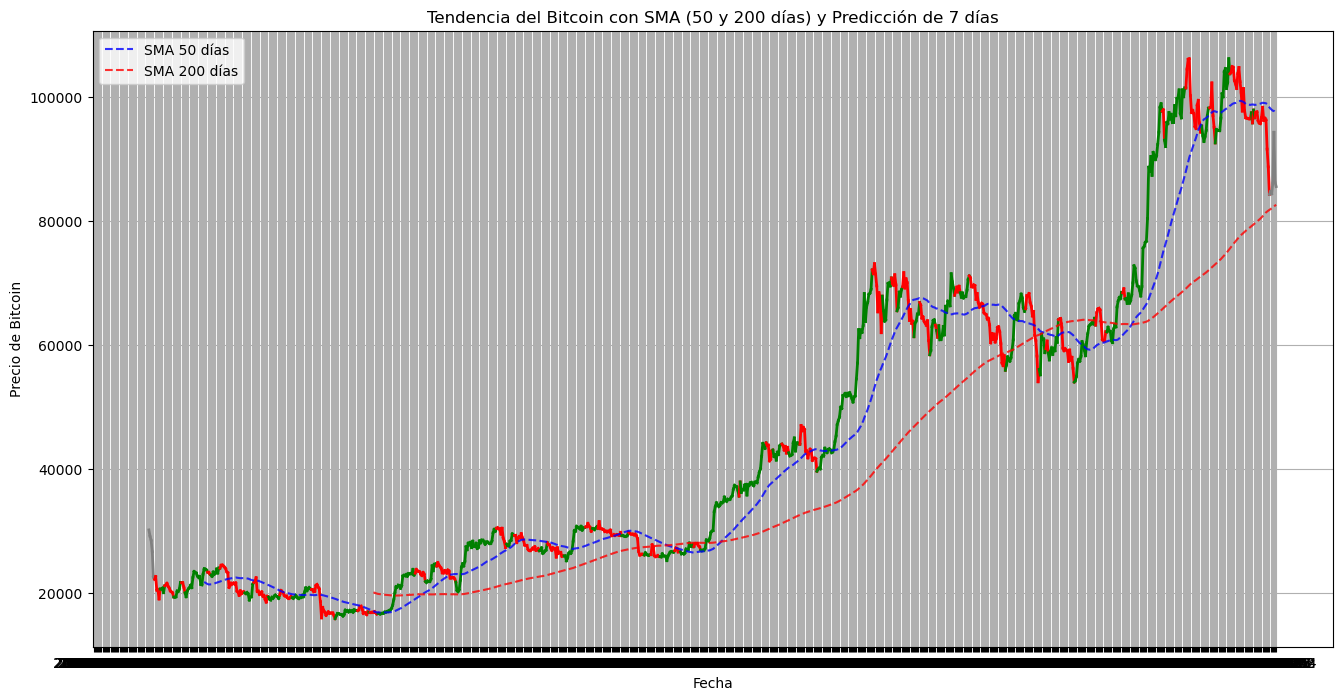

In [4]:
# Crear una visualización donde la línea de "close_binance" cambie de color según la tendencia futura
# Agregando un color adicional para la tendencia neutral

df_plot = df
# Configurar la figura
plt.figure(figsize=(16, 8))

# Recorrer el dataset para cambiar el color del precio de cierre según la tendencia
for i in range(1, len(df_plot)):
    if df_plot.iloc[i]['tendencia_futura_7d'] == 1:
        color = 'green'  # Alcista
    elif df_plot.iloc[i]['tendencia_futura_7d'] == -1:
        color = 'red'  # Bajista
    else:
        color = 'gray'  # Neutral

    plt.plot(df_plot['timestamp'].iloc[i-1:i+1], df_plot['close_binance'].iloc[i-1:i+1], color=color, linewidth=2)

# Graficar las medias móviles
plt.plot(df_plot['timestamp'], df_plot['SMA_50_binance'], label="SMA 50 días", linestyle="dashed", color="blue", alpha=0.8)
plt.plot(df_plot['timestamp'], df_plot['SMA_200_binance'], label="SMA 200 días", linestyle="dashed", color="red", alpha=0.8)

# Configuración de la gráfica
plt.xlabel("Fecha")
plt.ylabel("Precio de Bitcoin")
plt.title("Tendencia del Bitcoin con SMA (50 y 200 días) y Predicción de 7 días")
plt.legend()
plt.grid()

# Mostrar la gráfica mejorada con colores en la línea de precio
plt.show()

# Correlacion con variable respuesta

In [5]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volume_binance', 'trades_binance',
                 'Close_sp500', 'High_sp500', 'Low_sp500', 'Open_sp500', 'Volume_sp500',
                 'Close_nasdaq', 'High_nasdaq', 'Low_nasdaq', 'Open_nasdaq', 'Volume_nasdaq',
                 'Close_dxy', 'High_dxy', 'Low_dxy', 'Open_dxy', 'pct_cambio_7d', 'pct_cambio_30d']].dropna().corr(method='pearson')

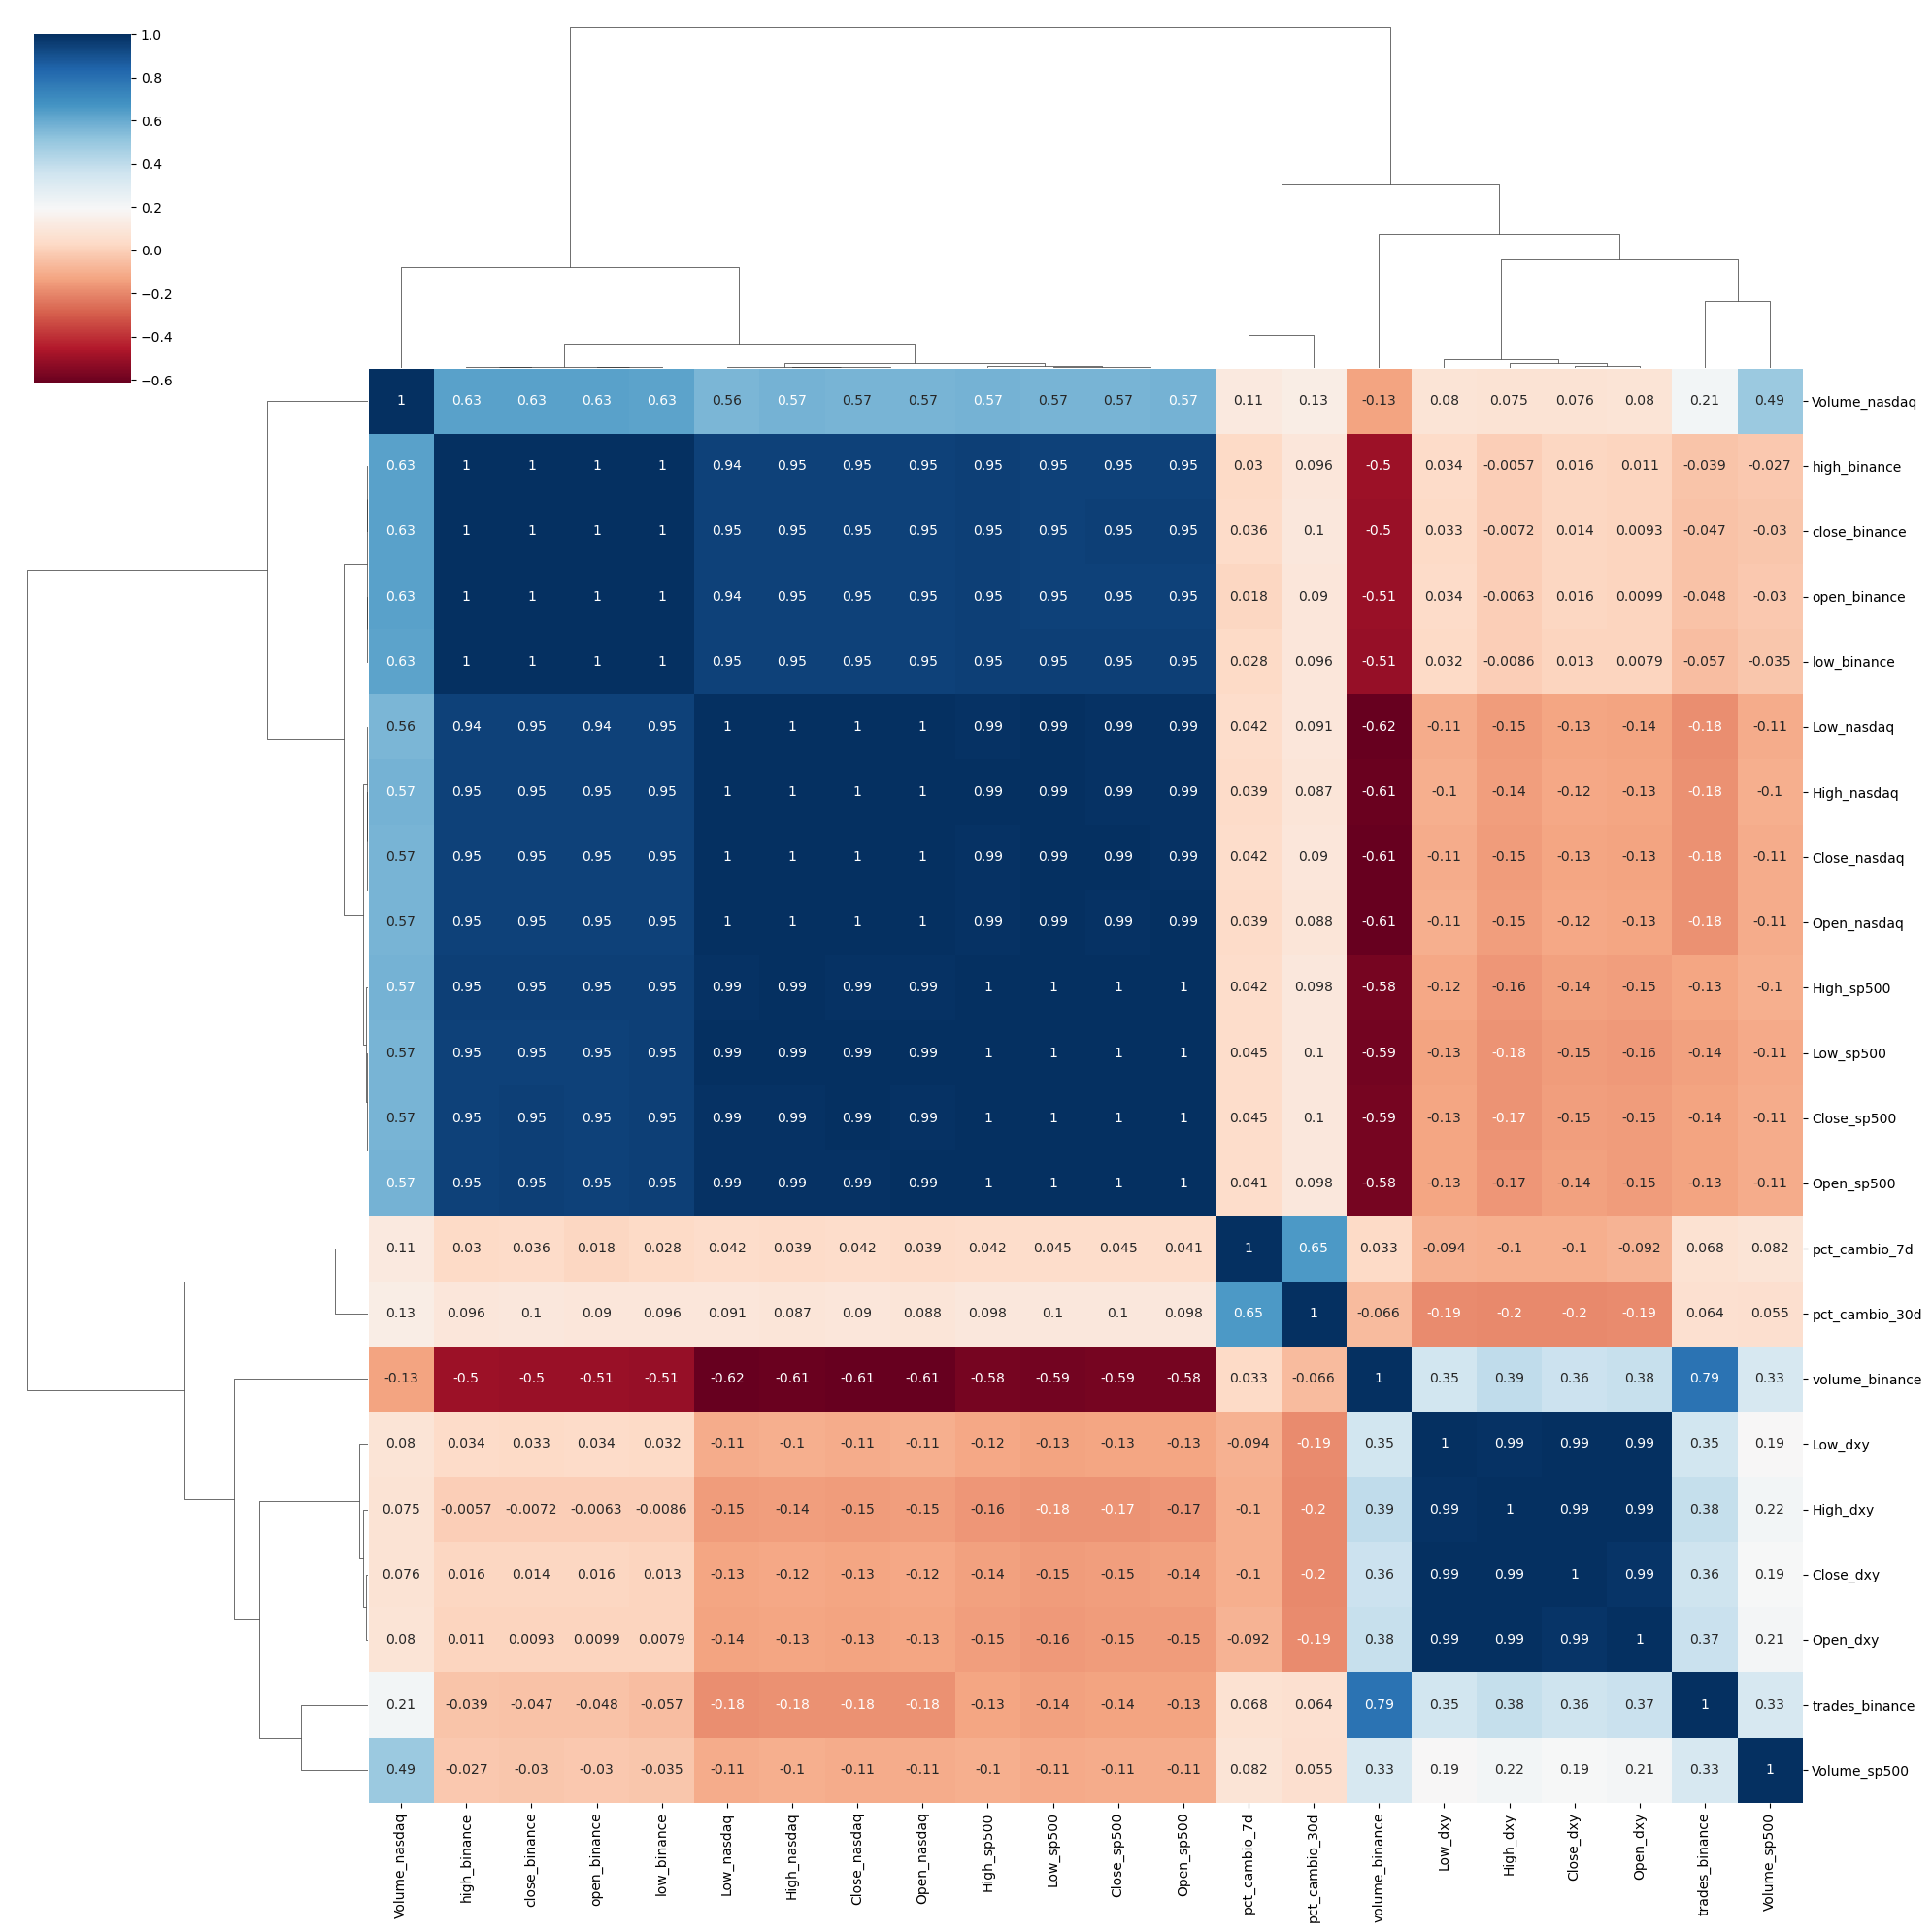

In [6]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()